## Exploring your own dataset

Having identified a dataset of interest to you, use this notebook to carry out whatever analyses you care to.  Remove the content from this Markdown cell, and populate the notebook with commentary, code, analyses, results, and figures as you see fit.

In [ ]:
# Load the EV data
# This dataset shows the Battery Electric Vehicles (BEVs) 
# and Plug-in Hybrid Electric Vehicles (PHEVs) that are currently registered through Washington State Department of Licensing (DOL).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading the data
ev_data='evdata.csv'
df = pd.read_csv(ev_data)

   VIN (1-10)    County        City State  Postal Code  Model Year   Make  \
0  3FMTK3SU8P      King     Seattle    WA      98177.0        2023   FORD   
1  JM3KKEHA8S  Thurston        Yelm    WA      98597.0        2025  MAZDA   
2  5YJ3E1EB8J      King   Sammamish    WA      98075.0        2018  TESLA   
3  JHMZC5F12K    Island  Oak Harbor    WA      98277.0        2019  HONDA   
4  1C4RJXN65R    Kitsap   Bremerton    WA      98312.0        2024   JEEP   

            Model                   Electric Vehicle Type  \
0  MUSTANG MACH-E          Battery Electric Vehicle (BEV)   
1           CX-90  Plug-in Hybrid Electric Vehicle (PHEV)   
2         MODEL 3          Battery Electric Vehicle (BEV)   
3         CLARITY  Plug-in Hybrid Electric Vehicle (PHEV)   
4        WRANGLER  Plug-in Hybrid Electric Vehicle (PHEV)   

   Clean Alternative Fuel Vehicle (CAFV) Eligibility  Electric Range  \
0  Eligibility unknown as battery range has not b...             0.0   
1              Not eligibl

In [5]:
# Viewing the data

print(df.shape)
print(df.head())
print(df.describe()) # numeric summary

(300142, 16)
   VIN (1-10)    County        City State  Postal Code  Model Year   Make  \
0  3FMTK3SU8P      King     Seattle    WA      98177.0        2023   FORD   
1  JM3KKEHA8S  Thurston        Yelm    WA      98597.0        2025  MAZDA   
2  5YJ3E1EB8J      King   Sammamish    WA      98075.0        2018  TESLA   
3  JHMZC5F12K    Island  Oak Harbor    WA      98277.0        2019  HONDA   
4  1C4RJXN65R    Kitsap   Bremerton    WA      98312.0        2024   JEEP   

            Model                   Electric Vehicle Type  \
0  MUSTANG MACH-E          Battery Electric Vehicle (BEV)   
1           CX-90  Plug-in Hybrid Electric Vehicle (PHEV)   
2         MODEL 3          Battery Electric Vehicle (BEV)   
3         CLARITY  Plug-in Hybrid Electric Vehicle (PHEV)   
4        WRANGLER  Plug-in Hybrid Electric Vehicle (PHEV)   

   Clean Alternative Fuel Vehicle (CAFV) Eligibility  Electric Range  \
0  Eligibility unknown as battery range has not b...             0.0   
1            

In [7]:
# Finding missing values
print(df.isna().sum().sort_values(ascending=False))  # missing values
# Finding duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Legislative District                                 790
Electric Range                                        35
Vehicle Location                                      24
2020 GEOID                                            15
Electric Utility                                      15
Postal Code                                           15
City                                                  15
County                                                15
DOL Vehicle ID                                         0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Vehicle Type                                  0
Model                                                  0
Make                                                   0
Model Year                                             0
State                                                  0
VIN (1-10)                                             0
dtype: int64
Duplicate rows: 0


In [8]:
# Clean the dataset
# Electric Range is often 0 when the value was never reported,
# so treat 0 as missing before averaging.
df["Electric Range"] = df["Electric Range"].replace(0, np.nan).astype(float)

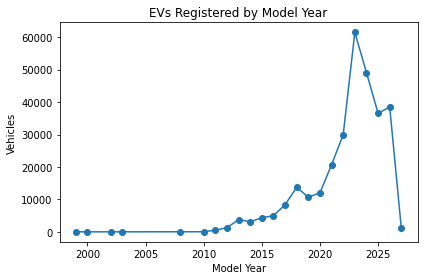

In [9]:
#Adoption over time (registered vehicles by model year)
by_year = df.groupby("Model Year").size()
by_year.plot(kind="line", marker="o", title="EVs Registered by Model Year")
plt.xlabel("Model Year"); plt.ylabel("Vehicles")
plt.tight_layout(); plt.show()

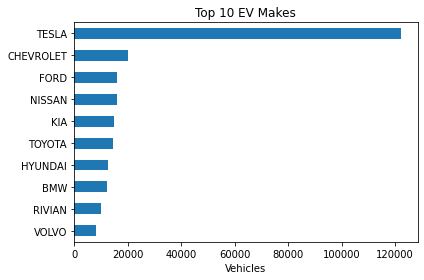

In [10]:
#Top 10 makes
top_makes = df["Make"].value_counts().head(10)
top_makes.sort_values().plot(kind="barh", title="Top 10 EV Makes")
plt.xlabel("Vehicles"); plt.tight_layout(); plt.show()

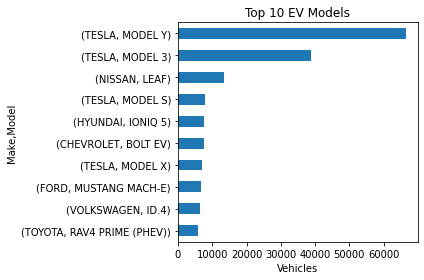

In [11]:
# Top 10 models (make + model)
top_models = (df.groupby(["Make", "Model"]).size()
                .sort_values(ascending=False).head(10))
top_models.sort_values().plot(kind="barh", title="Top 10 EV Models")
plt.xlabel("Vehicles"); plt.tight_layout(); plt.show()

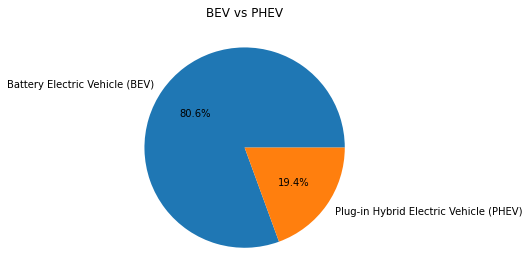

In [21]:
# BEV vs PHEV share
df["Electric Vehicle Type"].value_counts().plot(kind="pie", autopct="%1.1f%%",
                                  title="BEV vs PHEV")
plt.ylabel("")   # remove the default "count" label
plt.tight_layout(); plt.show()

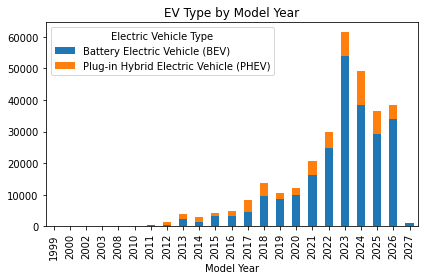

In [16]:
# BEV vs PHEV trend over time
type_year = df.groupby(["Model Year", "Electric Vehicle Type"]).size().unstack(fill_value=0)
type_year.plot(kind="bar", stacked=True, title="EV Type by Model Year")
plt.tight_layout(); plt.show()

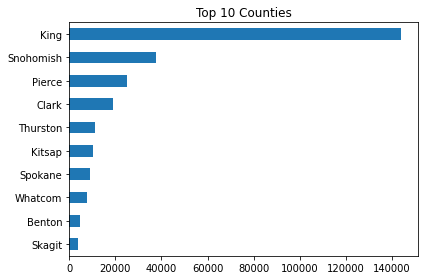

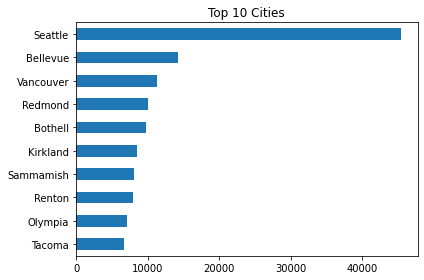

In [17]:
# Geography: top counties and cities
df["County"].value_counts().head(10).sort_values().plot(
    kind="barh", title="Top 10 Counties")
plt.tight_layout(); plt.show()
 
df["City"].value_counts().head(10).sort_values().plot(
    kind="barh", title="Top 10 Cities")
plt.tight_layout(); plt.show()

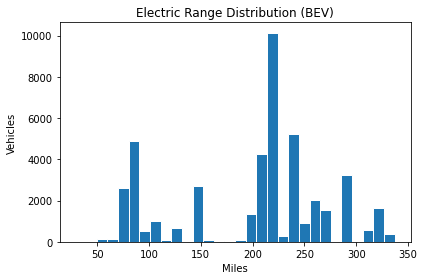

In [24]:
# Electric range distribution (BEVs only)
BEV = "Battery Electric Vehicle (BEV)"
PHEV = "Plug-in Hybrid Electric Vehicle (PHEV)"
bev = df[df["Electric Vehicle Type"] == BEV].dropna(subset=["Electric Range"])
plt.hist(bev["Electric Range"].astype(float), bins=30, edgecolor="white")
plt.title("Electric Range Distribution (BEV)")
plt.xlabel("Miles"); plt.ylabel("Vehicles")
plt.tight_layout(); plt.show()
 

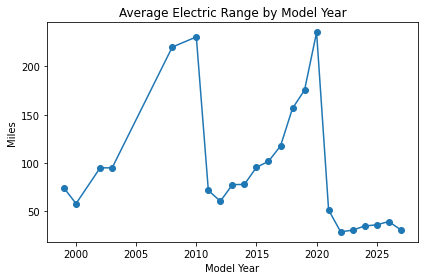

In [25]:
# Average range by model year
avg_range = (df.dropna(subset=["Electric Range"])
               .assign(**{"Electric Range": lambda d: d["Electric Range"].astype(float)})
               .groupby("Model Year")["Electric Range"].mean())
avg_range.plot(marker="o", title="Average Electric Range by Model Year")
plt.ylabel("Miles"); plt.tight_layout(); plt.show()

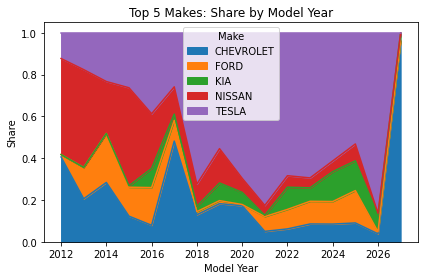

In [26]:
# Top makes' mix over time (market share shifts)
top5 = df["Make"].value_counts().head(5).index
share = (df[df["Make"].isin(top5) & (df["Model Year"] >= 2012)]
         .groupby(["Model Year", "Make"]).size().unstack(fill_value=0))
share = share.div(share.sum(axis=1), axis=0)
share.plot(kind="area", title="Top 5 Makes: Share by Model Year")
plt.ylabel("Share"); plt.tight_layout(); plt.show()

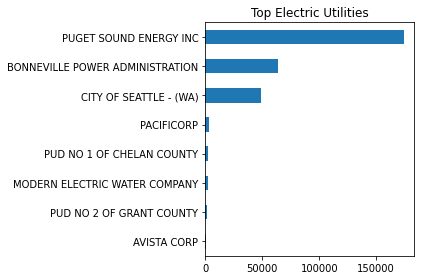

In [28]:
# Electric utilities serving the most EVs
(df["Electric Utility"].str.split("|").str[0]      # some rows list 2 utilities
   .value_counts().head(8).sort_values()
   .plot(kind="barh", title="Top Electric Utilities"))
plt.tight_layout(); plt.show()

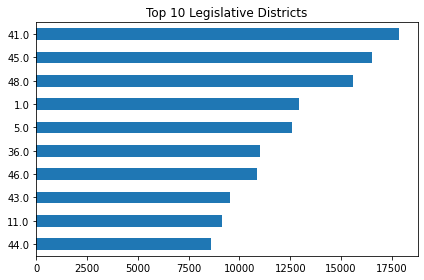

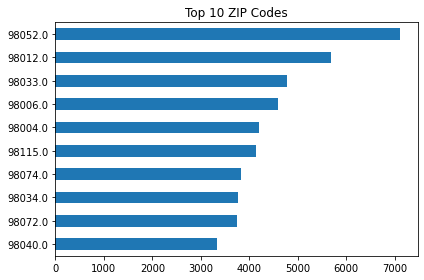

In [30]:
# Legislative districts and postal codes
df["Legislative District"].value_counts().head(10).sort_values().plot(
    kind="barh", title="Top 10 Legislative Districts")
plt.tight_layout(); plt.show()

df["Postal Code"].value_counts().head(10).sort_values().plot(
    kind="barh", title="Top 10 ZIP Codes")
plt.tight_layout(); plt.show()
 

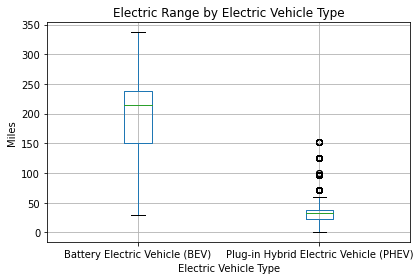

In [32]:
# Range: BEV vs PHEV (boxplot)
df.dropna(subset=["Electric Range"]).boxplot(
    column="Electric Range", by="Electric Vehicle Type")
plt.suptitle(""); plt.title("Electric Range by Electric Vehicle Type"); plt.ylabel("Miles")
plt.tight_layout(); plt.show()

In [33]:
print("\nKEY TAKEAWAYS")
print(f"Total EVs: {len(df):,}")
print(f"BEV share: {(df['Electric Vehicle Type'] == BEV).mean():.1%}")
print(f"Most common make: {top_makes.index[0]} ({top_makes.iloc[0]:,})")
print(f"Most common model: {top_models.index[0]}")
print(f"Top county: {df['County'].value_counts().index[0]}")
print(f"Peak model year: {by_year.idxmax()}")


KEY TAKEAWAYS
Total EVs: 300,142
BEV share: 80.6%
Most common make: TESLA (122,291)
Most common model: ('TESLA', 'MODEL Y')
Top county: King
Peak model year: 2023
